# Flux post-processing chain: IRGA72 CO2 flux (2016-2026.09)

**notebook version**: `10` (25 Oct 2026). Adapted from the diive notebook `FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

This notebook processes the CO2 flux (`FC`) of the closed-path **IRGA72** analyser. It adds the
storage term, removes poor-quality records and outliers, fills the gaps, and splits the flux into
gross primary production (GPP) and ecosystem respiration (RECO). The steps follow the levels of the
Swiss FluxNet workflow:

| Level | What it does | Function |
|---|---|---|
| L2 | Quality flags from the EddyPro output | `run_level2` |
| L3.1 | Adds the storage term | `run_level31` |
| L3.2 | Removes outliers | `make_level32_detector` + `run_level32` |
| L3.3 | Removes records with weak turbulence (USTAR filter), for three thresholds | `run_level33_constant_ustar` |
| L4.1 | Fills the gaps with XGBoost | `run_level41_xgb` |
| L4.2 | Splits the flux into GPP and RECO (nighttime and daytime method of ONEFlux) | `run_level42_partitioning` |

Each step takes the data and returns a new copy, so a step can be repeated without running the
earlier ones again.

**Test mode.** The notebook currently runs on one year (`YEARS`, in the settings cell). Level 4.2
is not part of this version of the dataset (`RUN_PARTITIONING = False`).

Level 2 and the USTAR thresholds are those of the 2016-2024 notebooks in this folder
(`01_FPC_L3.3_…` and `03_FPC_L4.1_…`). The other steps differ from them: the storage term is
screened for spikes (Level 3.1), the outlier tests are new (Level 3.2; the old notebooks used
absolute limits of ±50, trimming of low values and a local standard deviation test), and the gaps
are filled with XGBoost instead of a random forest (Level 4.1).

***

## 📇 Data sources

The input is `20_MERGE_DATA/IRGA72/22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet` in the
external data folder. It holds the Level-1 fluxes of all 18 `IRGA72` runs together with the meteo
data of `10_METEO/30_PRODUCTS/99`, from 1 January 2016 00:15 to 30 September 2026 23:45
(`TIMESTAMP_MIDDLE`, UTC+01:00). The flux columns are empty before the first `IRGA72` record on
11 January 2016.

**Meteo drivers.** Gap-filling and partitioning use three complete meteo series: air temperature
(`TA_T1_47_1_HOMOGENIZED_gfXG`), vapour pressure deficit (`VPD_T1_47_1_HOMOGENIZED`) and incoming
shortwave radiation (`SW_IN_T1_47_1_gfXG`). Temperature and VPD are the homogenised versions, which
correct for the probe changes in 2016 and June 2026. The ONEFlux partitioning also needs *measured*
temperature and radiation. Step 6 builds them from the same series by keeping only the records
flagged as measured (`ISFILLED` code `0`).

**Periods to keep in mind.**

- **Start-up of the LI-7200 in 2016.** During the installation (11 to 22 January) and a period with
  too low a flow rate (1 March to 25 May), water in the filter lowered the fluxes. Level 3.2 removes
  both periods by hand, as the 2016-2024 notebooks did.
- **19 May to 7 June 2018.** There is no `FC`. The flow module of the analyser had failed, so this
  period was processed with the sonic anemometer only.
- **Wrong calibration gas, 14 December 2017 to 15 March 2019.** All `IRGA72` CO2 concentrations of
  this period were calibrated against the wrong reference gas. The correction, a factor of 0.974 on
  the concentration, has to be applied before the flux is calculated. It was applied during the
  conversion of the raw data to ASCII with bico, so `FC` is already corrected.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\20_MERGE_DATA\IRGA72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# Years to process. None processes the whole record. A test run writes its own output file, so it
# never overwrites the result of a full run.
YEARS = [2025]
RUN_PARTITIONING = False  # Level 4.2, not part of this version of the dataset

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "01_FPPC_IRGA72_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\34_IRGA72_2016-2024"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the closed-path LI-7200; no self-heating correction is needed
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.2 ---------------------------------------------------------------------------------
# Start-up periods of the LI-7200 in 2016, removed by hand (date ranges, both ends included).
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],
    ['2016-03-01', '2016-05-25'],
]

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1), the 16th, 50th and 84th percentiles of the bootstrap
# detection of the 2016-2024 record (stage 32_). This dataset uses these fixed thresholds for the
# whole record.
USTAR_THRESHOLDS = [0.271619922, 0.303628125, 0.339684084]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
VPD_FLAG = 'FLAG_VPD_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
NIGHT_Z = 3  # night values below -NIGHT_Z times their uncertainty are removed in Level 3.2

# 30-min CO2 flux in umol m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# MDS gap-filling, next to XGBoost, to compare the two methods. mode='diive' fills every gap,
# also long ones; the QC flags keep model-filled driver values out of the similar samples.
RUN_MDS = True
MDS_SETTINGS = dict(mode='diive', fill_long_gaps=True)

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=350, max_depth=6, learning_rate=0.05,
                    early_stopping_rounds=10, random_state=42, n_jobs=-1, shap_max_rows=5000)

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_mds,
    run_level41_xgb,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_gapfilled_cumulative,
    plot_gapfilling_comparison,
    plot_gapfilling_input,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_comparison,
    report_gapfilling_feature_importances,
    report_gapfilling_input,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_gaps,
    report_model_overview,
    report_traintest_model_scores,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-26 11:01:11
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"

for _c in [FLUXCOL, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet (0.335 seconds).

17,520 records x 347 columns, 2025-01-01 00:15:00 -> 2025-12-31 23:45:00
FC: 17,404 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 17520 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The same tests as in the 2016-2024 notebooks: steady state and developed turbulence (SSITC), the
size of the spectral correction factor, the signal strength of the LI-7200 (records below 60 are
removed), and spikes and dropouts in the raw data (Vickers and Mahrt 1997). Gas completeness is not
tested. In practice SSITC removes nearly all rejected records: over 2016-2026.09 the dropout test
never fails and the spike test fails for about 34 records.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 13,768 valid records


### 📊 Plot: Level-2 quality flag over time

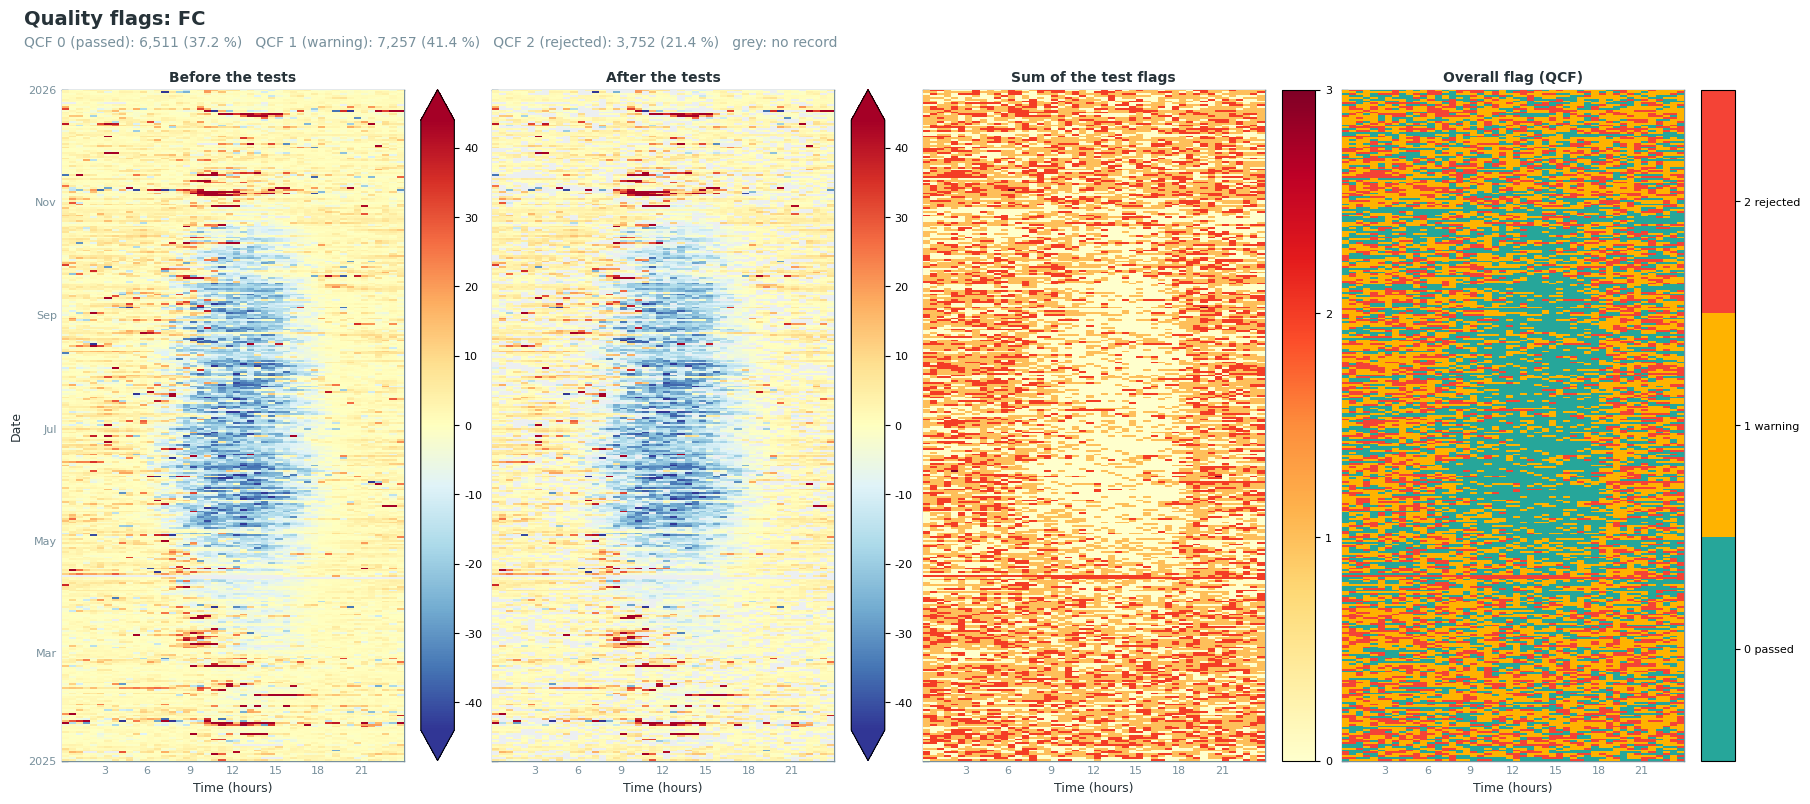

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 17,404 of 17,520
Missing records: 116 (0.66 %), flagged by the missing-values test
                                                Pass    Warn    Fail    Fail      Not
Test                        Period   Tested      (0)     (1)     (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      17,404    6,514   7,258   3,632   20.87        0
                            day       8,651    3,915   3,350   1,386   16.02        0
                            night     8,753    2,599   3,908   2,246   25.66        0
                                                                                     
L2_FC_SCF                   all      17,404   17,393       8       3    0.02        0
                            day       8,651    8,646       5       0    0.00        0
                            night     8,753    8,747       3       3    0.03        0
                                                                                     
L2_FC_SIGNAL_STRENGTH       all      17,404   17,403       0       1   <0.01        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,752       0       1    0.01        0
                                                                                     
L2_FC_CO2_VM97_SPIKE_HF     all      17,404   17,404       0       0    0.00        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,753       0       0    0.00        0
                                                                                     
L2_FC_CO2_VM97_DROPOUT_HF   all      17,404   17,404       0       0    0.00        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,753       0       0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`FC + SC_SINGLE`). The storage term comes from a single CO2
profile point and has spikes. A spike would make a good flux record an outlier, and Level 3.2 would
remove the record. Isolated spikes are therefore found first, with a Hampel filter on the double
differences of the storage term (13 days, 5.5 sigma, one pass). A run of more than three flagged
values in a row is kept as measured: such a run is a noisy period, not a spike. Each spike run,
together with one record on either side, is replaced by the mean of its measured values. The
storage term is the change in CO2 concentration, so the sum over such a block is the real change
across it; keeping the sum keeps the storage term balanced, and a single spike is spread over three
records. Gaps in the storage term are filled with a rolling median, so every measured flux keeps a
storage term.

In [8]:
data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False,
                   screen_storage_term=True)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

> Storage term SC_SINGLE: 500 spike(s) found (2.88 % of the measured storage values)

> Storage term SC_SINGLE: 1,085 value(s) replaced by the mean of their block (spikes and one 
record on either side)

After L3.1: 13,768 valid records (col: NEE_L3.1_QCF)


### 📊 Plot: storage term screening

Checks that the screened and filled storage term still behaves like a storage term. The mean daily
cycle should stay positive at night and dip in the morning, when the CO2 that built up overnight is
released. The spikes should spread over the day with both signs; a cluster of negative spikes in the
morning would mean that real release was replaced. Over a year the storage term should sum
to about zero, and the gap between the two cumulative lines is the effect of the screening on the
sum of the flux.

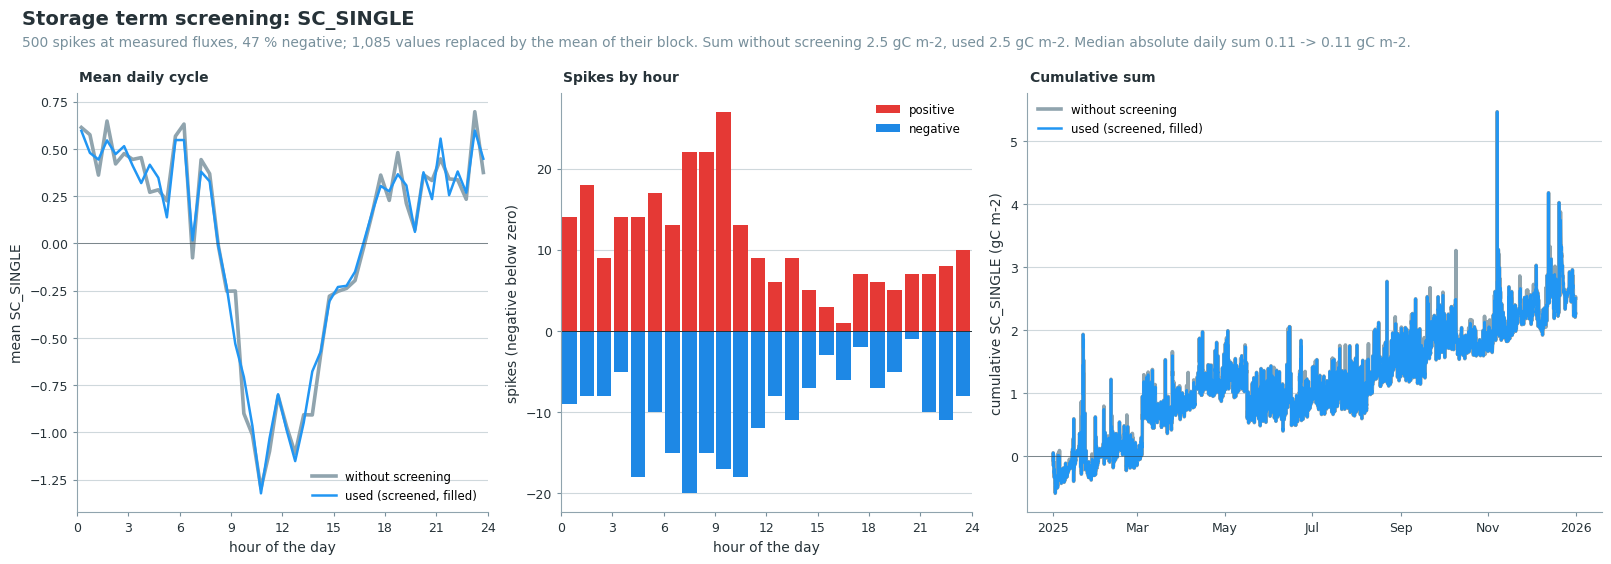

In [9]:
data.levels.level31.plot_screening(gain=UMOL_TO_GC, units='gC m-2');

## Step 4: outlier removal (Level 3.2)

Four tests:

1. Remove the 2016 start-up periods of the LI-7200 by hand. Skipped when the processed years do not
   include them.
2. Hampel filter on the double differences of neighbouring records. It finds single spikes.
3. Hampel filter on the values per time of day. Each record is compared with the records of the
   same half-hour, and of the half-hours before and after it, over 13 days. It finds values that
   are wrong for their time of day, such as noon-like uptake at sunrise, and runs of high values
   that the double differences do not catch.
4. Remove nighttime values clearly below zero, see *Negative values at night* below.

Both Hampel filters use 5.5 sigma by day and by night, over 13 days.

Each test first draws its plot. Check the plot, then run the cell below it, `sod.addflag()`, to
accept the test. A test that is not accepted removes nothing.

diive has more outlier tests. The table at the end of this step lists them. To add one, call its
method on `sod` in a new cell before *Apply the Level-3.2 flags*, check its plot, and accept it with
`sod.addflag()` in the cell after it.

In [10]:
data, sod = make_level32_detector(data)

### 📊 Plot: 2016 start-up periods, removed by hand

In [11]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

No manual removal dates in 2025-01-01 - 2025-12-31; test skipped.


In [12]:
if _remove:
    sod.addflag()  # accept the manual removal

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:   444 (  3.22%) | Day:   228 | Night:   216

[Dt/Nt] ITER #02 | Outliers:   100 (  0.75%) | Day:    50 | Night:    50

[Dt/Nt] ITER #03 | Outliers:    25 (  0.19%) | Day:    16 | Night:     9

[Dt/Nt] ITER #04 | Outliers:     4 (  0.03%) | Day:     2 | Night:     2

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

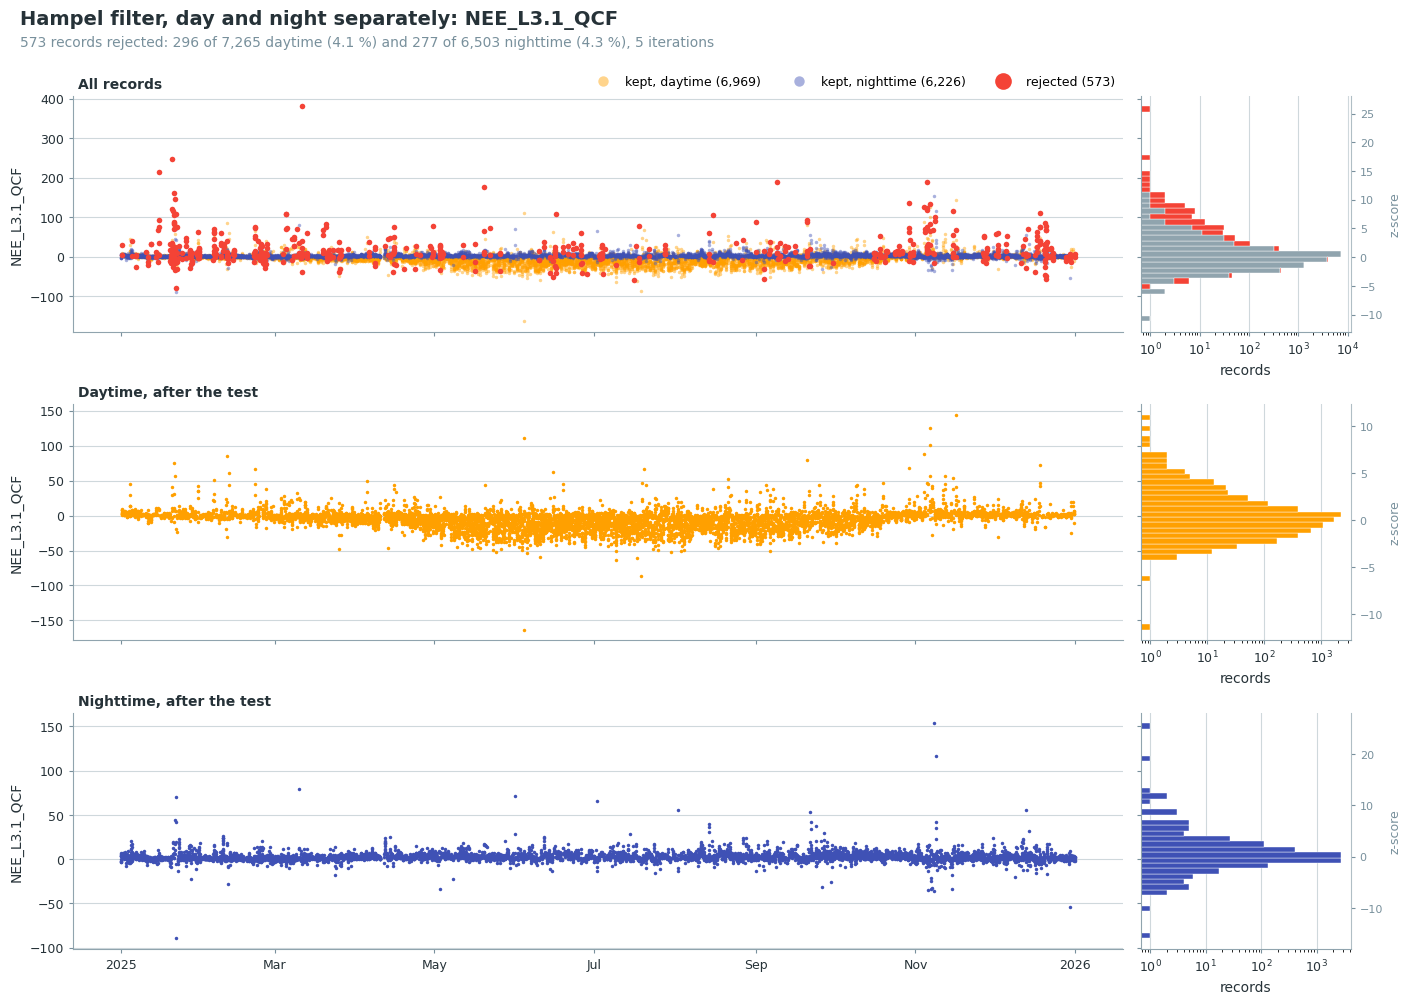

In [13]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [14]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values per time of day

[Dt/Nt] ITER #01 | Outliers:   260 (  1.97%) | Day:   120 | Night:   140

[Dt/Nt] ITER #02 | Outliers:    29 (  0.22%) | Day:    14 | Night:    15

[Dt/Nt] ITER #03 | Outliers:     1 (  0.01%) | Day:     0 | Night:     1

[Dt/Nt] ITER #04 | Outliers:     1 (  0.01%) | Day:     0 | Night:     1

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

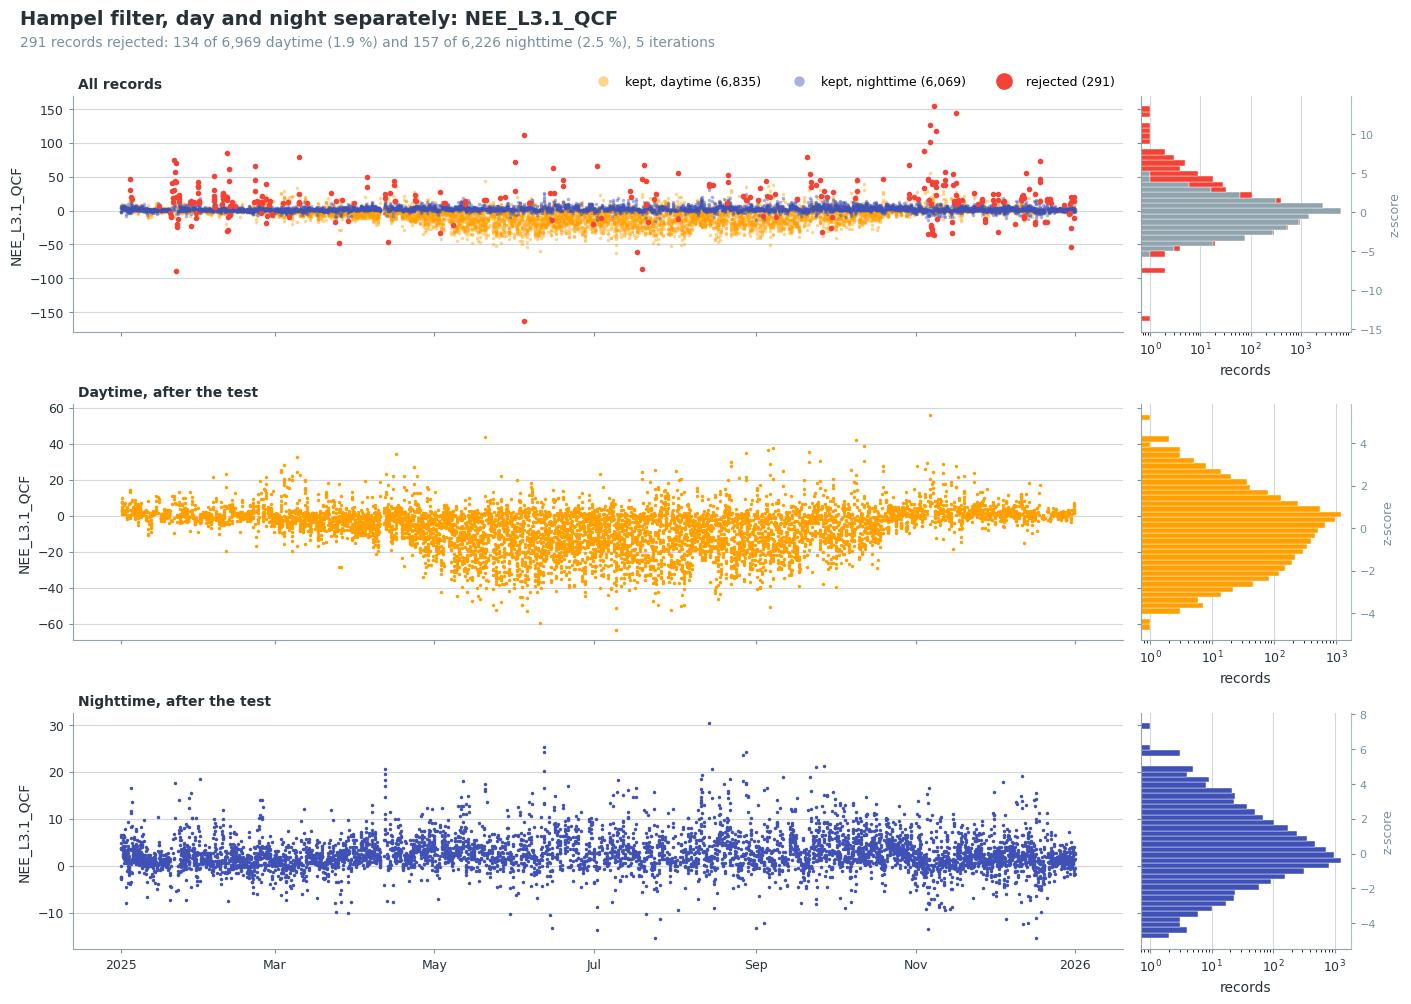

In [15]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              by_time_of_day=True, time_of_day_slots=1, min_records=10,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [16]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### Negative values at night

At night there is no photosynthesis, so the flux is respiration and its true value is zero or above.
A measured value can still be negative: random noise around a small respiration pushes some records
below zero. Such a value is plausible if it lies within a few times its random uncertainty (sigma)
of zero. A value below `-NIGHT_Z * sigma` is not, and test 4 removes it. Daytime values are not
tested, because by day both signs are real.

Removing every negative value would cut off one side of the noise and raise the nighttime flux. The
test therefore removes only the values that noise cannot explain. Its plot reports how many of the
removed records noise alone would have produced. If that number is small, the test removes errors,
not noise.

Sigma is the larger of two uncertainties for each record:

- **FS**: the uncertainty EddyPro gives for each half-hour (`FC_RANDUNC_HF`). It covers only the
  sampling error of that half-hour's covariance, so it is small.
- **PAS20**: the random uncertainty of FLUXNET2015 and ONEFlux, the spread of measured fluxes under
  similar conditions within days of each record. It also holds real differences between the
  fluxes, so it is a generous estimate of the random error. It is computed from the records the
  Hampel filters kept, so that outliers do not widen it.

With the larger of the two, a value counts as clearly below zero only if neither explains it.

### 📋 Table: random uncertainty of the nighttime records

In [17]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

Random uncertainty of the 6,069 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.68      515 (8.5 %)      359 (5.9 %)
PAS20                    2.96       38 (0.6 %)        2 (0.0 %)
MAX                      2.97       34 (0.6 %)        1 (0.0 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two.

### 📊 Plot: nighttime values clearly below zero

> Nighttime records below -3 uncertainties: 1. Expected from noise alone (Gaussian): 1.0 records, 
raising the sum by 15.54 (flux units x records) once their gaps are filled.

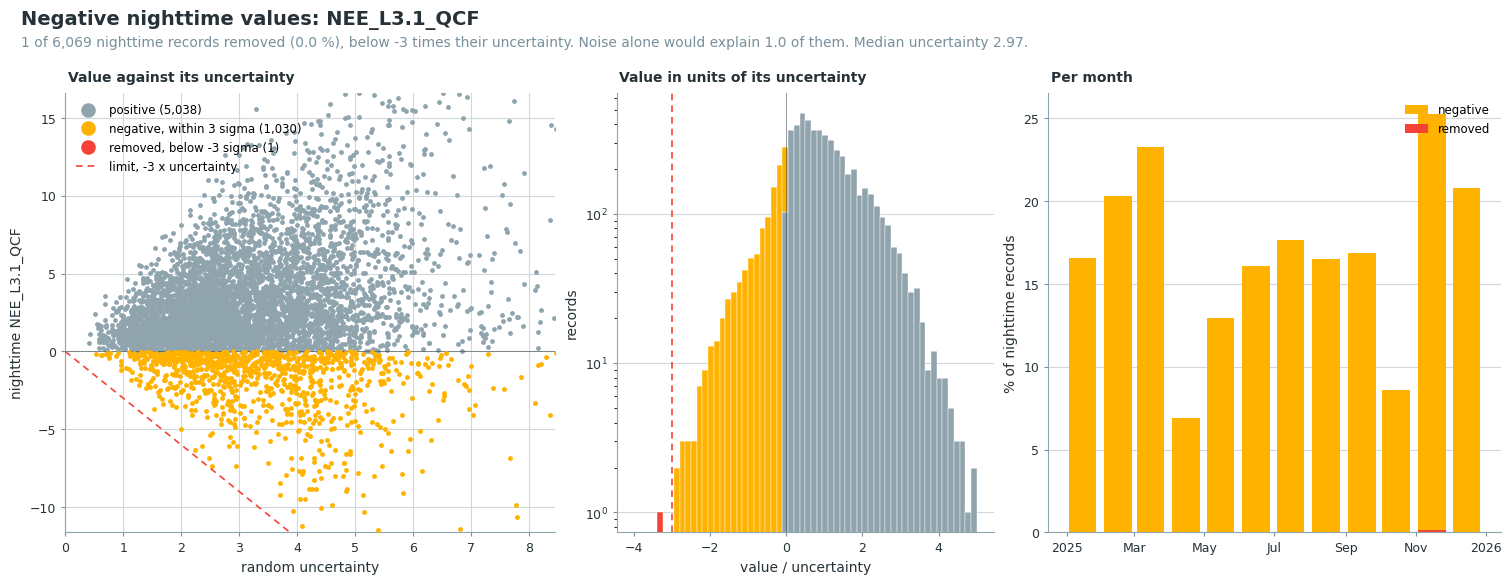

In [18]:
sod.flag_outliers_negative_night_test(uncertainty=sigma['MAX'], z=NIGHT_Z, showplot=True, verbose=True)

In [19]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [20]:
_used = {'flag_manualremoval_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [21]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 12,903 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

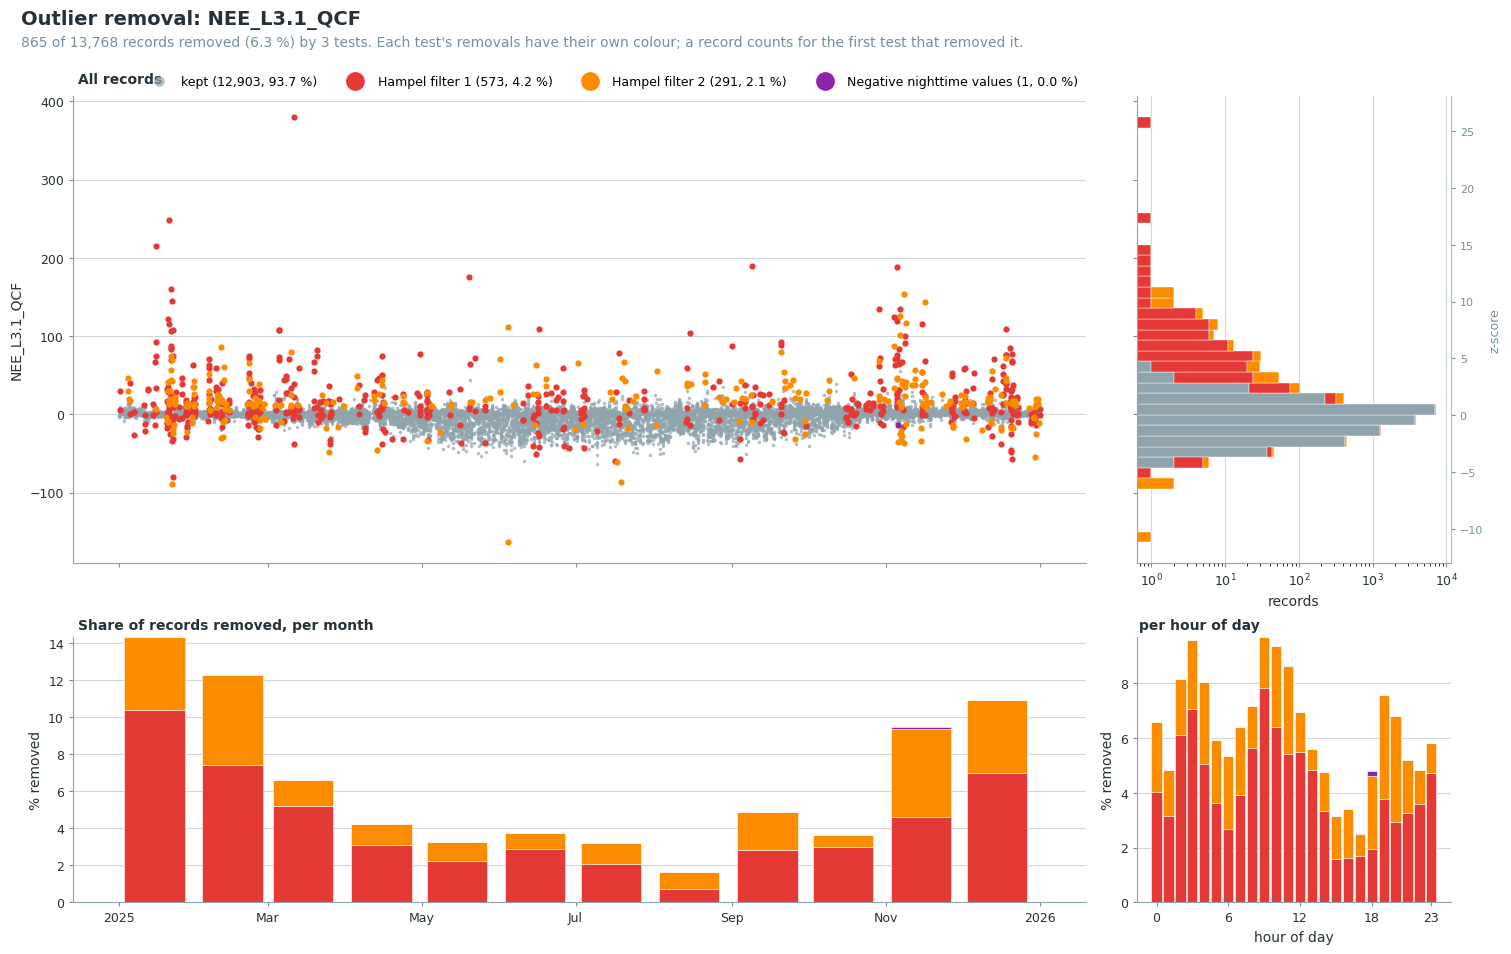

In [22]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

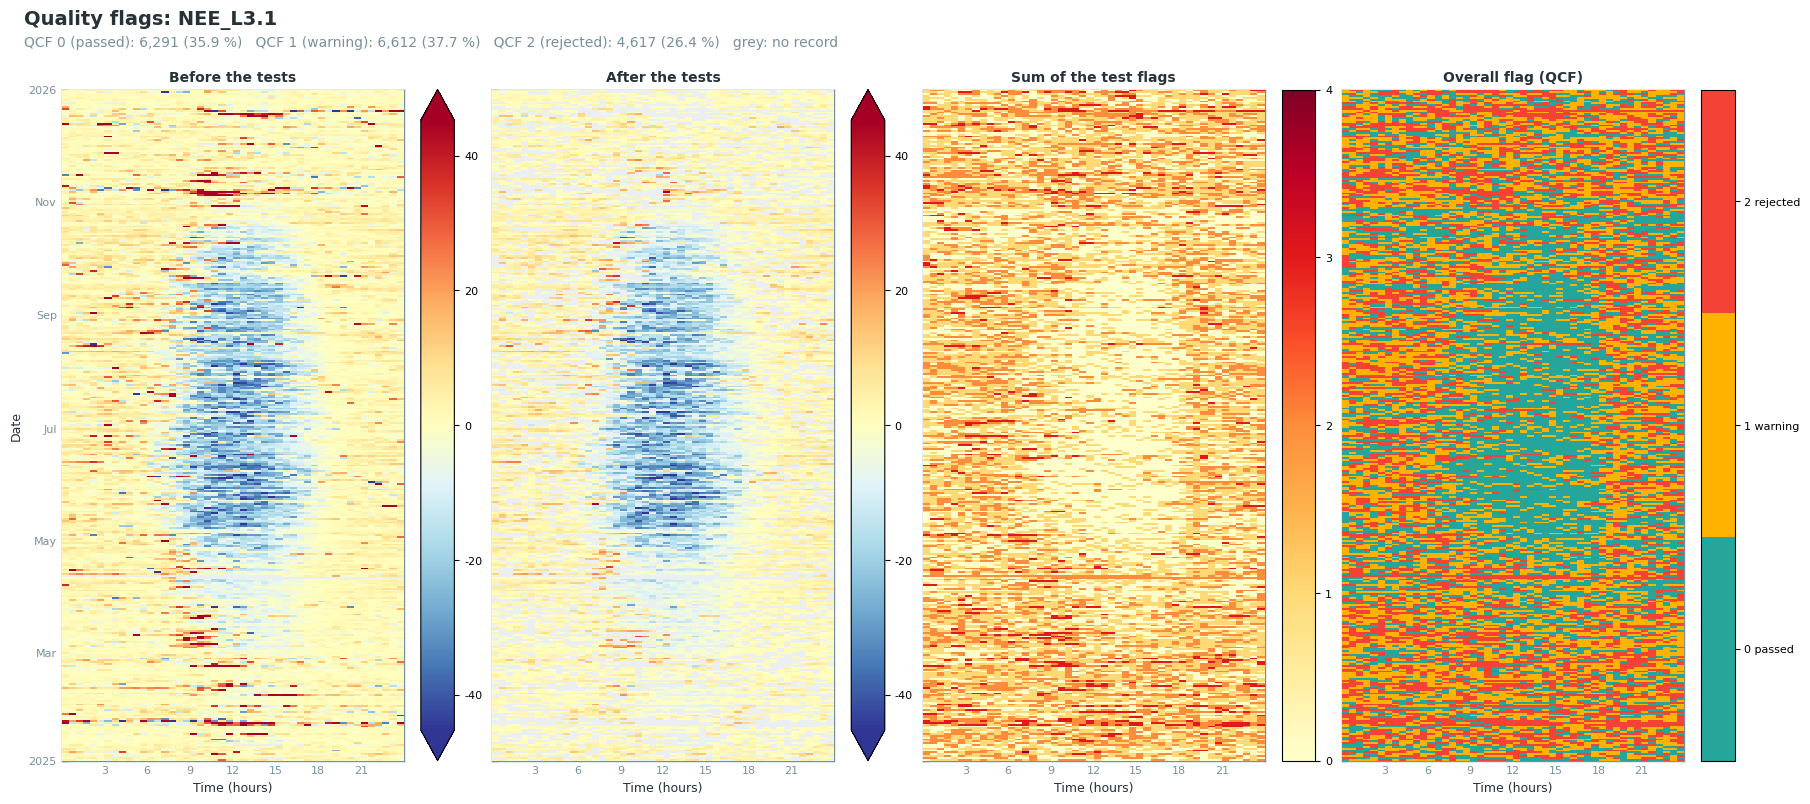

In [23]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [24]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 17,404 of 17,520
Missing records: 116 (0.66 %), flagged by the missing-values test
                                                         Pass    Warn    Fail    Fail      Not
Test                                 Period   Tested      (0)     (1)     (2)       %   tested
──────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                          all      17,404    6,514   7,258   3,632   20.87        0
                                     day       8,651    3,915   3,350   1,386   16.02        0
                                     night     8,753    2,599   3,908   2,246   25.66        0
                                                                                              
L2_FC_SCF                            all      17,404   17,393       8       3    0.02        0
                                     day       8,651    8,646       5       0    0.00        0
                                     night     8,753    8,747       3       3    0.03        0
                                                                                              
L2_FC_SIGNAL_STRENGTH                all      17,404   17,403       0       1   <0.01        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,752       0       1    0.01        0
                                                                                              
L2_FC_CO2_VM97_SPIKE_HF              all      17,404   17,404       0       0    0.00        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,753       0       0    0.00        0
                                                                                              
L2_FC_CO2_VM97_DROPOUT_HF            all      17,404   17,404       0       0    0.00        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,753       0       0    0.00        0
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL     all      13,768   13,195       0     573    4.16    3,636
                                     day       7,265    6,969       0     296    4.07    1,386
                                     night     6,503    6,226       0     277    4.26    2,250
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2   all      13,195   12,904       0     291    2.21    4,209
                                     day       6,969    6,835       0     134    1.92    1,682
                                     night     6,226    6,069       0     157    2.52    2,527
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT   all      12,904   12,903       0       1   <0.01    4,500
                                     day       6,835    6,835       0       0    0.00    1,816
                                     night     6,069    6,068       0       1    0.02    2,684

## Step 5: USTAR filter (Level 3.3)

Removes records with weak turbulence, where the friction velocity (USTAR) is below a threshold, by
day and by night, as ONEFlux does. Unlike ONEFlux, the first record above the threshold after a
period below it is kept. Records without USTAR are removed too. There are three scenarios,
one per threshold: the 16th, 50th and 84th percentile of the threshold detection on the 2016-2024
record. These fixed thresholds are used for the whole record. From here on each scenario has its own
series, so `data.filteredseries` is empty.

In [25]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

### Records for gap-filling and highest-quality records

After Level 3.3 every measured record that failed a test or the USTAR filter is removed. What is
left depends on two settings: the USTAR scenario, and the quality flags that are accepted
(`DAYTIME_ACCEPT_QCF_BELOW` and `NIGHTTIME_ACCEPT_QCF_BELOW`, here 2, so QCF 0 and 1). These records
are what the gap-filling starts from.

The highest-quality records (QCF 0) passed every test without a warning. Use them for analyses that
need measured values only, without gap-filled ones. The output file holds them in one column per
scenario, ending in `_L3.3_<scenario>_QCF0`; the records for gap-filling end in `_L3.3_<scenario>_QCF`.

### 📋 Table: records per USTAR scenario

In [26]:
report_gapfilling_input(data);

Records for gap-filling
                    removed:   removed:           used:   used:   used:   used:
USTAR    measured      tests      USTAR    used   QCF 0   QCF 1     day   night
───────────────────────────────────────────────────────────────────────────────
CUT_16     17,404      4,501      3,347   9,556   5,395   4,161   5,551   4,005
              99%        26%        19%     55%     31%     24%     32%     23%
CUT_50     17,404      4,501      3,965   8,938   5,142   3,796   5,240   3,698
              99%        26%        23%     51%     29%     22%     30%     21%
CUT_84     17,404      4,501      4,664   8,239   4,822   3,417   4,855   3,384
              99%        26%        27%     47%     28%     20%     28%     19%
Records, and their share of all 17,520 records of the period.
removed: tests = quality tests and outlier detection (Levels 2 to 3.2).
used = records for gap-filling: QCF below 2 by day and below 2 by night. QCF 0 is the highest 
quality, the measured flux for analyses without gap-filled values.

### 📊 Plot: records for gap-filling and highest-quality records

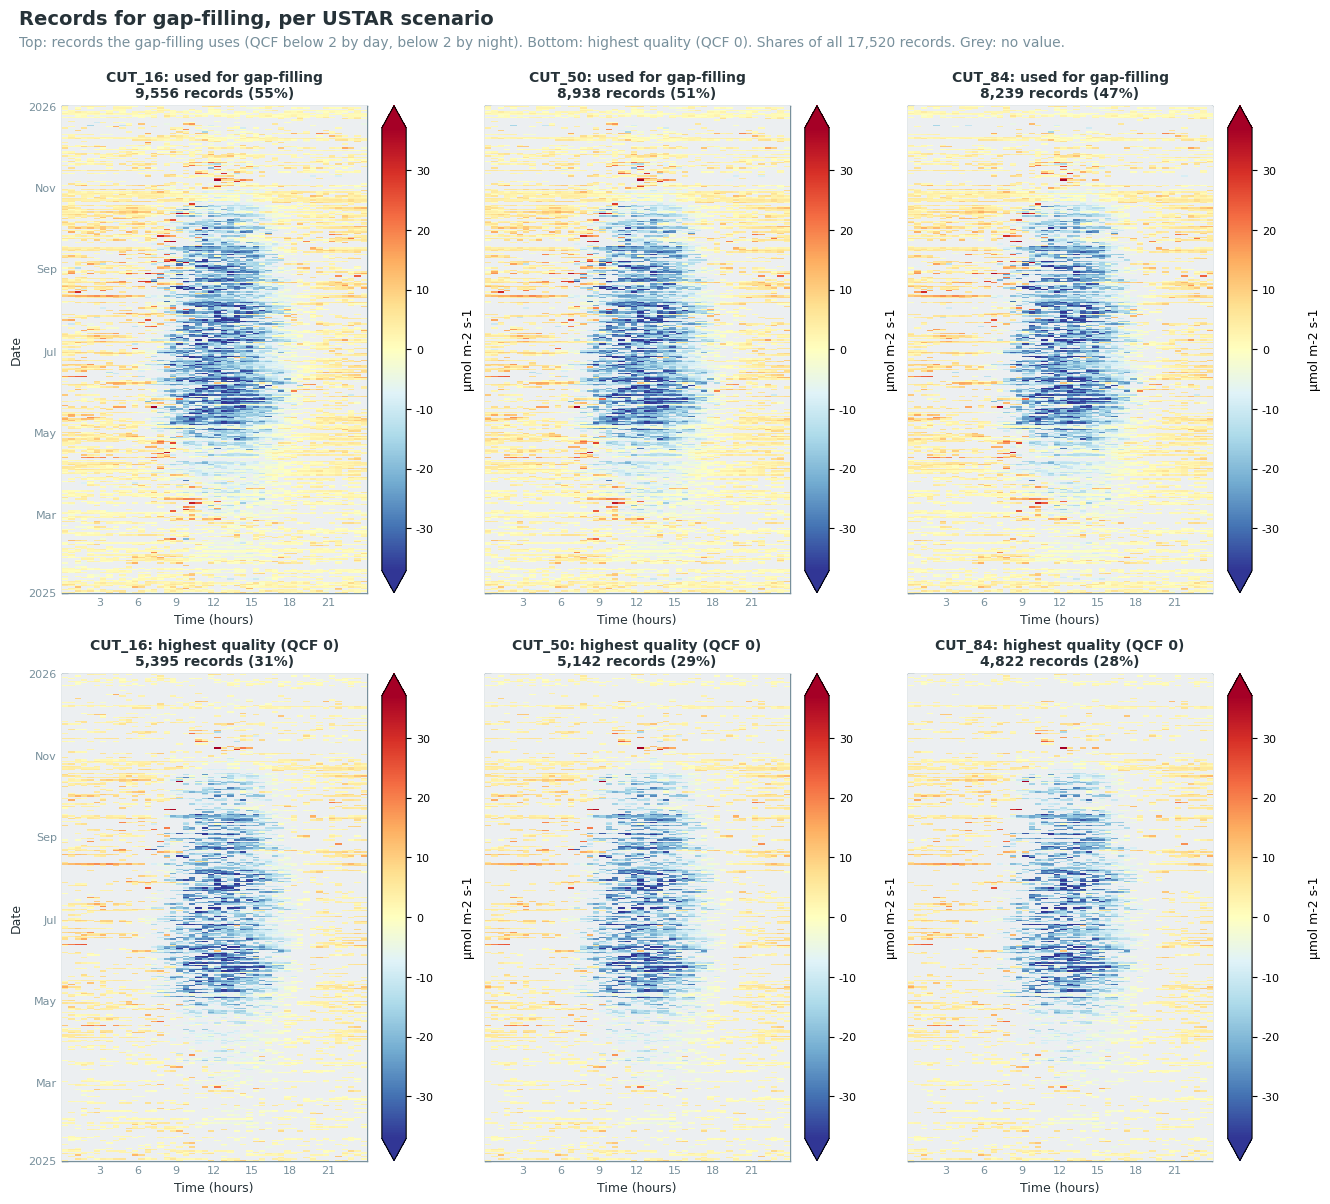

In [27]:
plot_gapfilling_input(data, units=FLUX_UNITS)

### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day.

In [28]:
report_gaps(data, long_gap_days=1);

Gaps to fill
USTAR    missing %   gaps   long gaps   longest gap (days)   worst month   worst month missing %
────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16        45.5   2333           5                  1.3           Nov                    62.1
CUT_50        49.0   2229           5                  2.4           Dec                    66.7
CUT_84        53.0   2117           8                  3.2           Dec                    70.2
A long gap lasts at least 1 day.

## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the records measured at 47 m. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [29]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 17,519 measured records of 17,520
SW_IN_T1_47_1_MEASURED: 17,520 measured records of 17,520


## Step 7: gap-filling (Level 4.1)

Two methods fill the gaps of each USTAR scenario: XGBoost, the method of this dataset, and MDS,
the standard method of FLUXNET, for comparison. Step 11 compares the two.

### XGBoost

Each year gets its own model for each USTAR scenario, trained on that year and its two neighbouring
years. SHAP values select the features: a feature is kept if it is clearly more important than a
random variable. Every scenario then uses the features that any scenario selected, so the scenarios
differ in their records, not in their features.

In [30]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

### MDS

Marginal distribution sampling (Reichstein et al. 2005) fills each gap with the mean of measured
fluxes under similar conditions: incoming radiation, air temperature and VPD within set
tolerances, in a time window that widens until enough similar records are found. `mode='diive'`
takes a symmetric mean by day (Vekuri et al. 2023) and fills every gap, also long ones, because
this dataset needs complete years. Only measured driver values serve as similar records (the
`ISFILLED` flags of the drivers). MDS predicts each measured record without using it, so its
scores are out-of-sample.

**Skipped** when `RUN_MDS = False`.

In [31]:
if RUN_MDS:
    data = run_level41_mds(
        data,
        swin=SW_IN_F, ta=TA_F, vpd=VPD_F,  # W m-2, degC, kPa
        swin_qc=SW_IN_FLAG, ta_qc=TA_FLAG, vpd_qc=VPD_FLAG,
        **MDS_SETTINGS,
    )

─────────────────────────────────── Level 4.1: Gap-Filling (MDS) ───────────────────────────────────

## Step 8: partitioning into GPP and RECO (Level 4.2)

**Not part of this version of the dataset** (`RUN_PARTITIONING = False`).

Splits the flux into GPP and RECO for each USTAR scenario, with both methods as ONEFlux implements
them (the code used by ICOS and FLUXNET). The nighttime method (Reichstein et al. 2005) fits the
temperature response of the nighttime flux. The daytime method (Lasslop et al. 2010) fits a light
response curve to the daytime flux. Both fit the measured flux and use the gap-filled flux of
Level 4.1 to compute GPP. Their output columns end in `_NT_OF` and `_DT_OF`. ONEFlux itself
partitions a flux filled with MDS, so these columns are not identical to ONEFlux output.

In [32]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method='xgb',
    )

In [33]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method='xgb',
    )
    print(data.partitioned_cols())

## Step 9: results

How many records were measured and how many were filled, then the annual sum of the flux, for each
USTAR scenario. In 2016 about 108 days have no measurements (see the per-year plot below), so its
sum rests largely on the model. 2026 ends on 30 September.

### 📋 Table: measured and filled records

In [34]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR    records   measured   filled   filled %
─────────────────────────────────────────────────────────
MDS       CUT_16    17,520      9,556    7,964       45.5
MDS       CUT_50    17,520      8,938    8,582       49.0
MDS       CUT_84    17,520      8,239    9,281       53.0
XGBoost   CUT_16    17,520      9,556    7,964       45.5
XGBoost   CUT_50    17,520      8,938    8,582       49.0
XGBoost   CUT_84    17,520      8,239    9,281       53.0
MDS (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfMDS
MDS (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfMDS
MDS (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfMDS
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG

### 📋 Table: annual sums of the flux

In [35]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
              MDS          MDS          MDS      XGBoost      XGBoost      XGBoost
year       CUT_16       CUT_50       CUT_84       CUT_16       CUT_50       CUT_84
──────────────────────────────────────────────────────────────────────────────────
2025   -487 (55%)   -464 (51%)   -458 (47%)   -420 (55%)   -393 (51%)   -389 (47%)
In brackets: the share of the year's records that were measured.

## Step 10: model quality

First the scores on test data: a random 25 % of the complete records, which the model did not see in
training. Early stopping uses a part of the training data, not the test data. Because the test
records lie between training records, the scores describe short gaps better than gaps of several
days.

### 📋 Table: scores on test data

In [36]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2025   0.783   5.23   3.37    2.05   37.3
XGBoost   CUT_50   2025   0.786   5.24   3.36    2.01   53.7
XGBoost   CUT_84   2025   0.789   5.34   3.42    2.04   49.2
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84).

### 📋 Table: gap-filling models per year

How each model was built and how well it did: the years it was trained on, its features, the
training and test records, the number of trees early stopping chose, the records of the final fit,
the test scores, and how the gaps of its year were filled.

In [37]:
report_model_overview(data);

Gap-filling models
                trained                                        final    test   test            fall-
USTAR    year   on        features   train    test     trees     fit      R²   RMSE   filled    back
────────────────────────────────────────────────────────────────────────────────────────────────────
CUT_16   2025   2025            56   7,167   2,389   124/350   9,556   0.783   5.23    7,964       0
                                                                                                    
CUT_50   2025   2025            56   6,703   2,235   163/350   8,938   0.786   5.24    8,582       0
                                                                                                    
CUT_84   2025   2025            56   6,179   2,060    73/350   8,239   0.789   5.34    9,281       0
Each year has its own model, trained on that year and its neighbours ('trained on').
train / test: a random 75 / 25 % split of the complete records; the test scores come from the 25 %, 
which the model did not see.
trees: with early stopping, the number it chose on 10 % of the training records, out of the maximum;
at the maximum, more trees might still help.
final fit: the gaps are filled by a model refitted on all complete records with that number of 
trees. filled / fallback: gaps of the model year filled by this model, or by the fallback model on 
timestamp features where a driver was missing.
XGBoost: early_stopping_rounds=10, learning_rate=0.05, max_depth=6, n_estimators=350, n_jobs=-1, 
random_state=42

Next the scores on all measured records. The gaps are filled by a model refitted on all of them, so
these scores are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [38]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
MDS       CUT_16   all    0.707   5.99   3.85    2.32   57.0
MDS       CUT_50   all    0.717   5.98   3.85    2.32   57.6
MDS       CUT_84   all    0.725   6.00   3.86    2.35   57.6
XGBoost   CUT_16   2025   0.890   3.68   2.52    1.65   24.9
XGBoost   CUT_50   2025   0.907   3.43   2.37    1.59   22.3
XGBoost   CUT_84   2025   0.881   3.95   2.67    1.71   31.9
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
MDS predicts each measured record without using it, so its scores are out-of-sample and not 
comparable with those of the ML methods; report_gapfilling_comparison scores both on the same 
held-out records.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [39]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2025         2025                   
Not available for MDS (CUT_16), MDS (CUT_50), MDS (CUT_84) (does not pool years).

### 📋 Table: most important features (SHAP), CUT_16

In [40]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_16')

Feature importances, XGBoost (CUT_16): top 10 of 56 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.516
 2   .DOY_COS                           1.875
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.603
 4   .HOUR_COS                          0.960
 5   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.474
 6   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.455
 7   .SW_IN_T1_47_1_gfXG_MEAN4          0.445
 8   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.330
 9   .VPD_T1_47_1_HOMOGENIZED+2         0.304
10   .DOY_SIN                           0.302

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_16) (no model trained).

### 📋 Table: most important features (SHAP), CUT_50

In [41]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_50')

Feature importances, XGBoost (CUT_50): top 10 of 56 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.390
 2   .DOY_COS                           1.931
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.606
 4   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.987
 5   .HOUR_COS                          0.902
 6   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.391
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.379
 8   .SW_IN_T1_47_1_gfXG_MEAN4          0.356
 9   .DOY_SIN                           0.341
10   .VPD_T1_47_1_HOMOGENIZED+2         0.321

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_50) (no model trained).

### 📋 Table: most important features (SHAP), CUT_84

In [42]:
report_gapfilling_feature_importances(data, ustar_scenario='CUT_84')

Feature importances, XGBoost (CUT_84): top 10 of 56 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.308
 2   .DOY_COS                           2.032
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.468
 4   .SW_IN_T1_47_1_gfXG_ROLLMAX2       1.214
 5   .HOUR_COS                          0.849
 6   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.530
 7   .DOY_SIN                           0.337
 8   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.333
 9   .VPD_T1_47_1_HOMOGENIZED+2         0.259
10   .SW_IN_T1_47_1_gfXG_MEAN4          0.210

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).
Not available for MDS (CUT_84) (no model trained).

### 📊 Plot: feature ranks per year

> MDS (CUT_16): no feature ranks available.

> MDS (CUT_50): no feature ranks available.

> MDS (CUT_84): no feature ranks available.

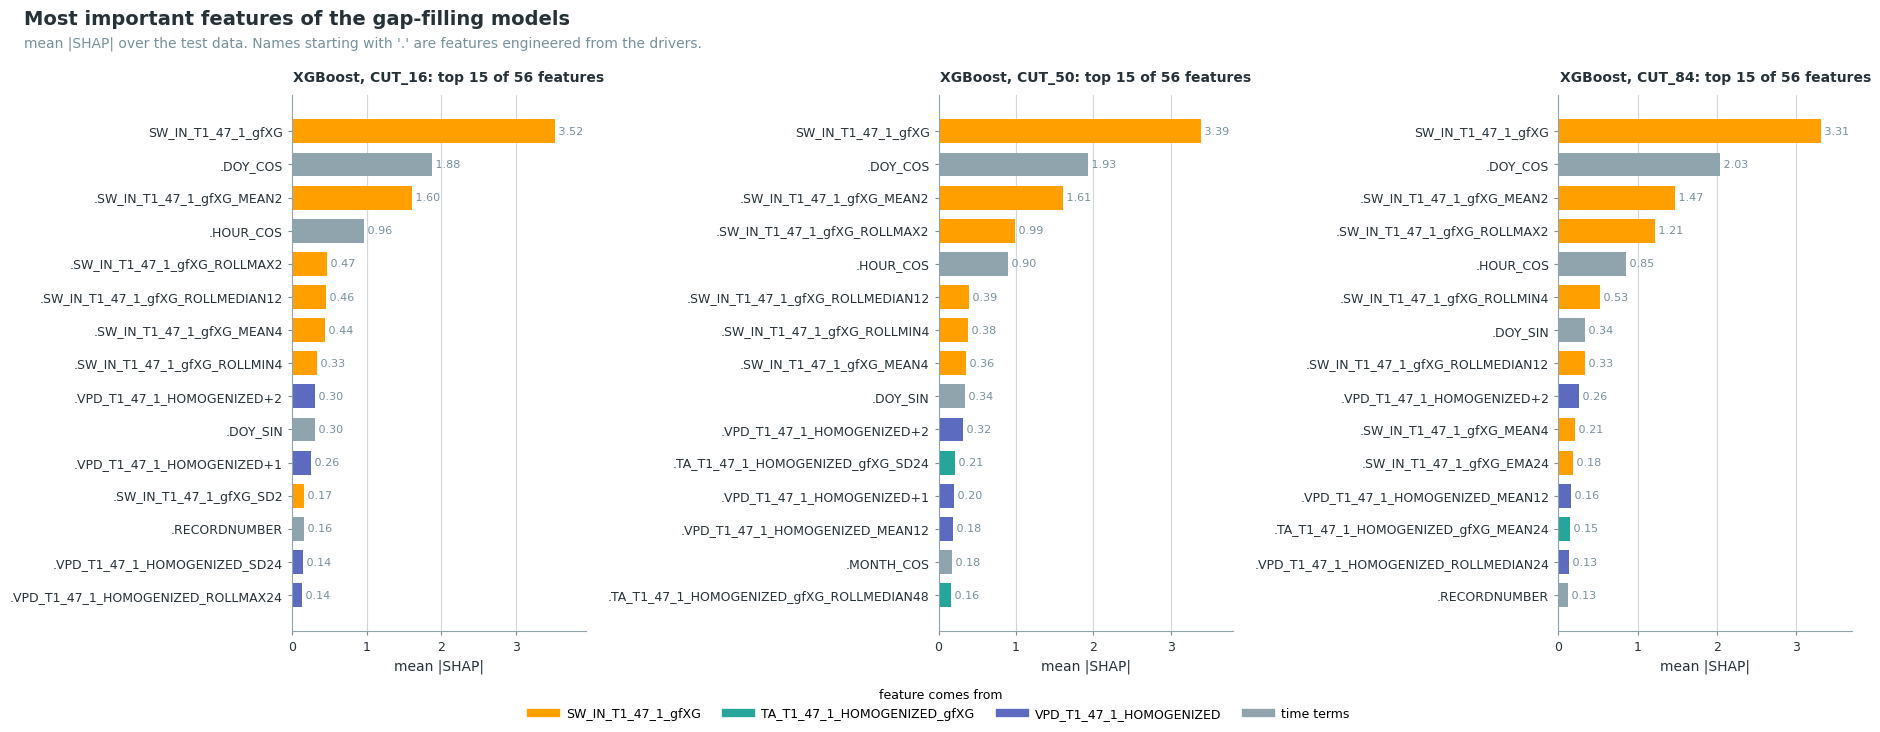

In [43]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: flux by quality class, heatmaps, XGBoost, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

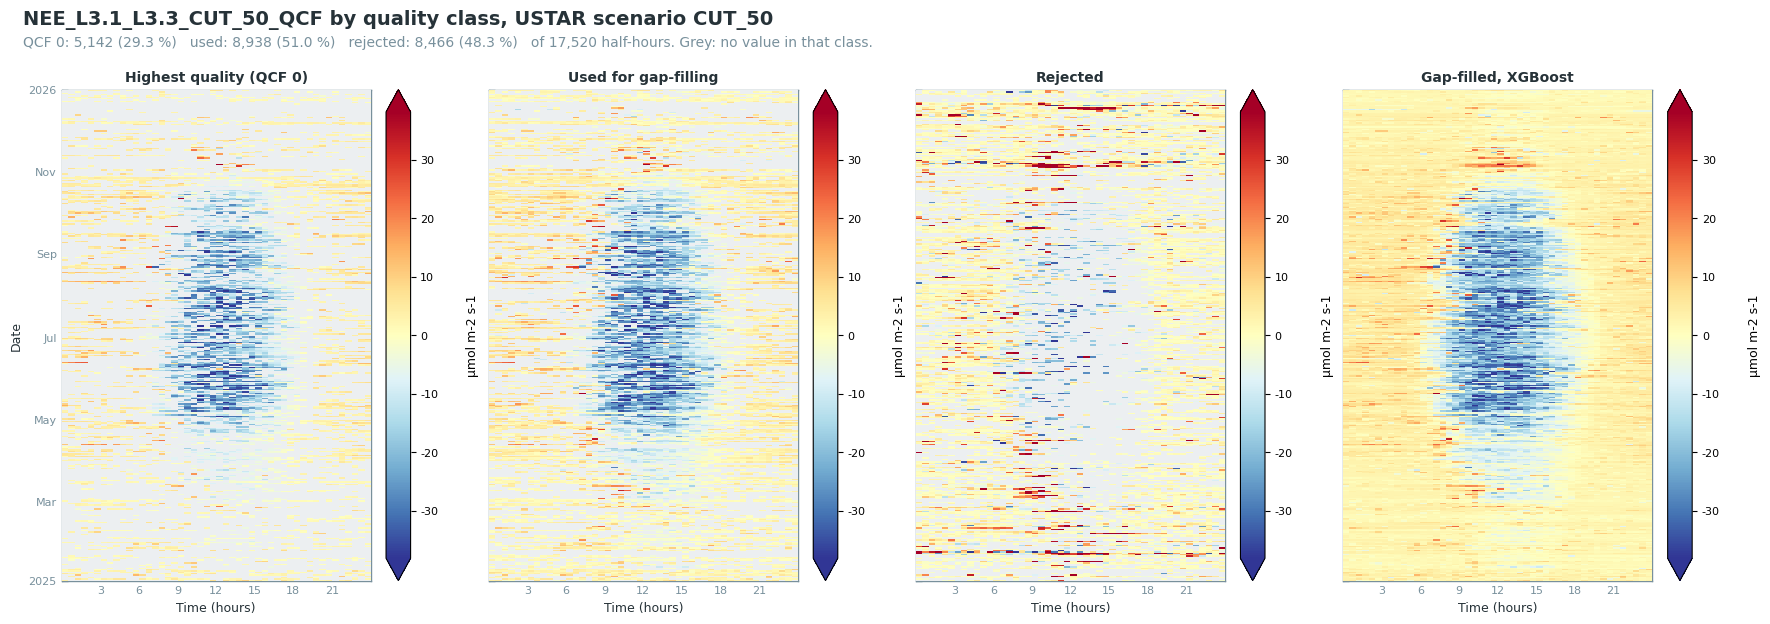

In [44]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: flux by quality class, day and night, XGBoost, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result, with measured and
filled records shown apart.

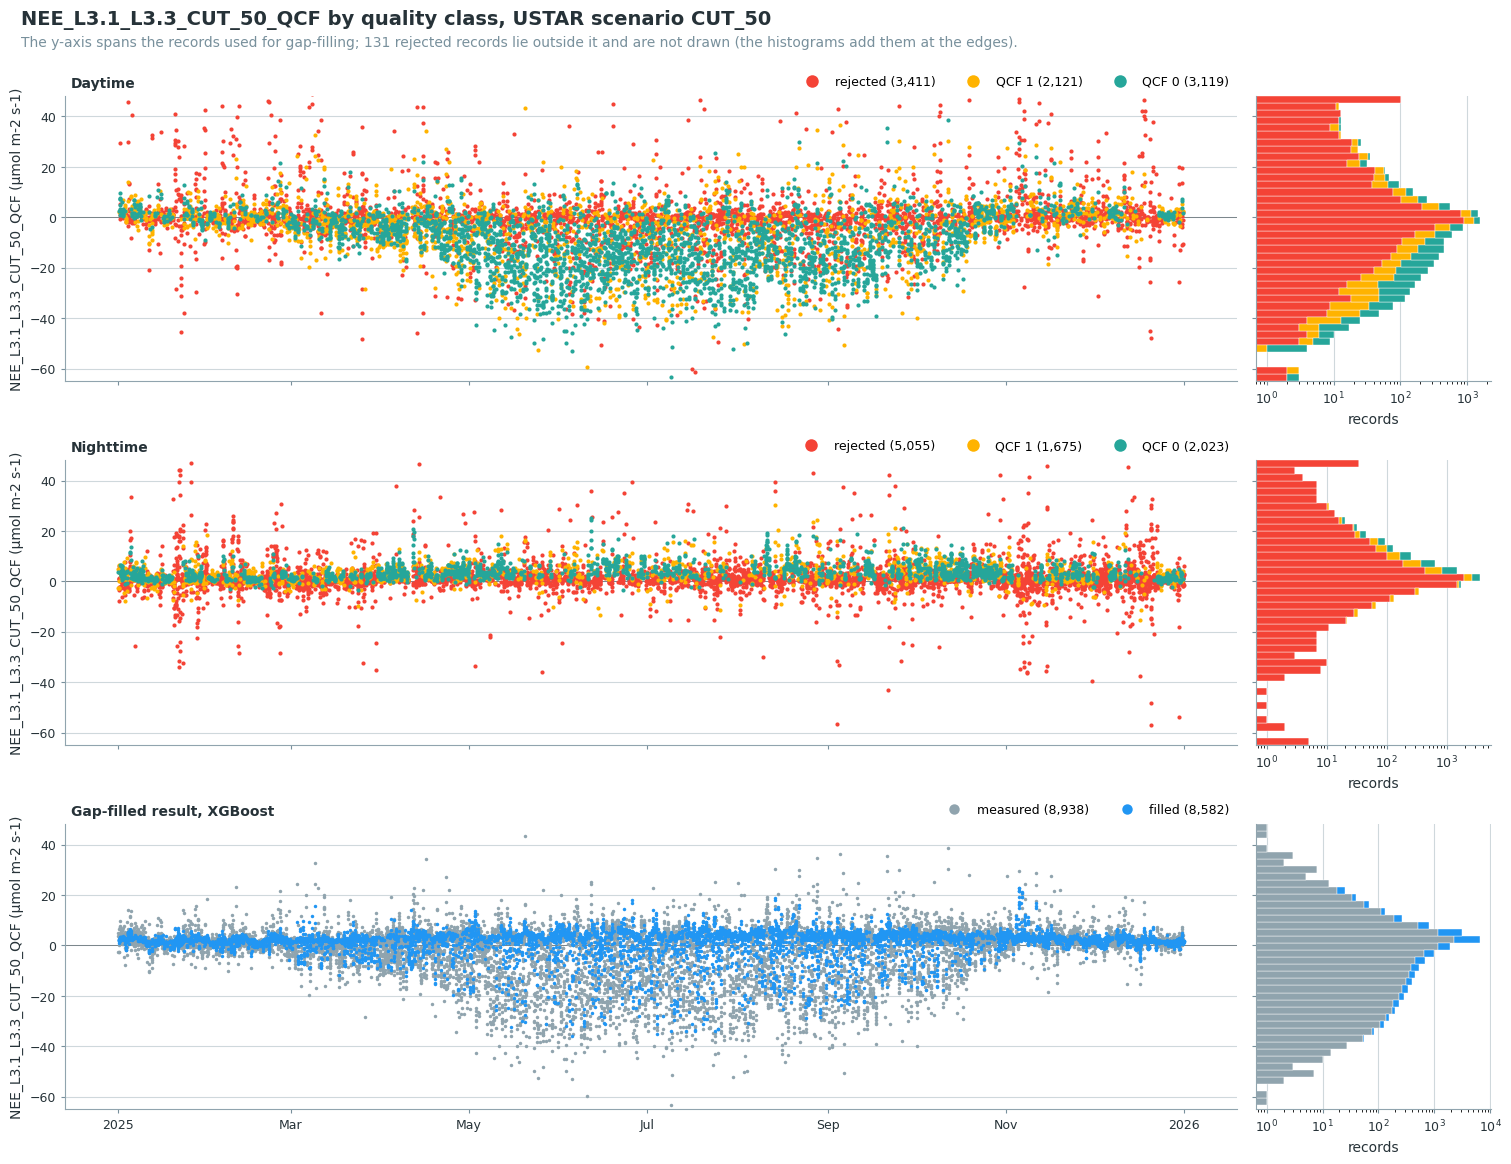

In [45]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS, method='xgb')

### 📊 Plot: measured and gap-filled flux, CUT_50

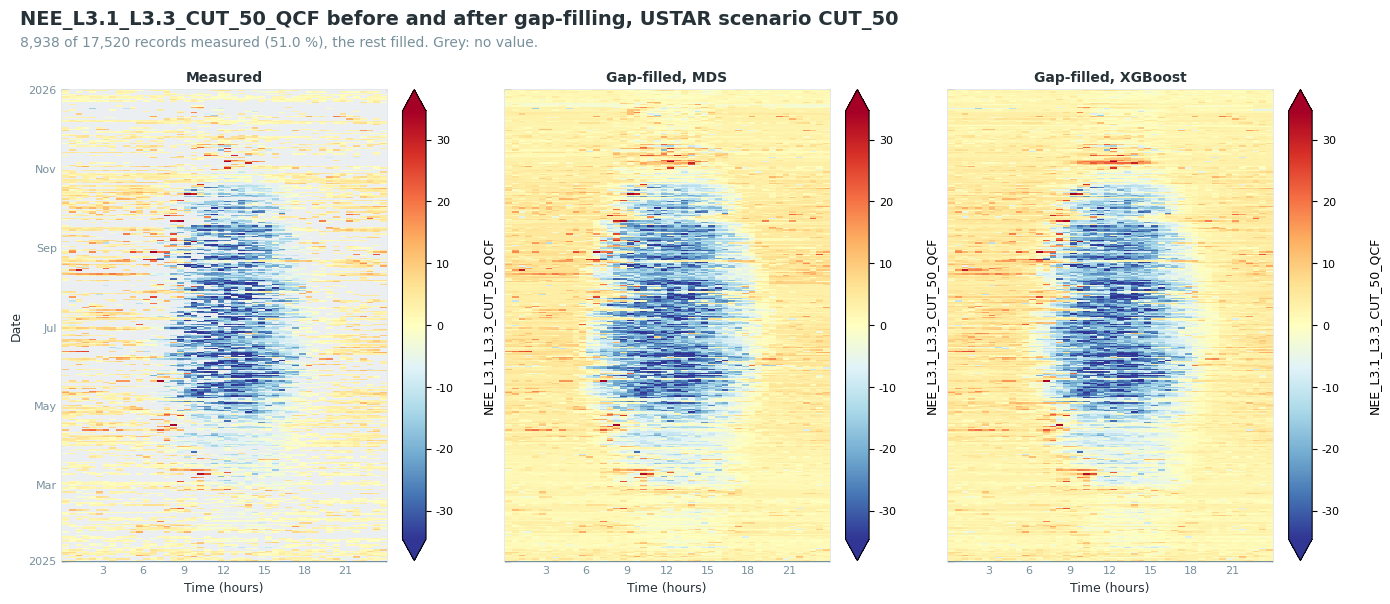

In [46]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative flux, CUT_50

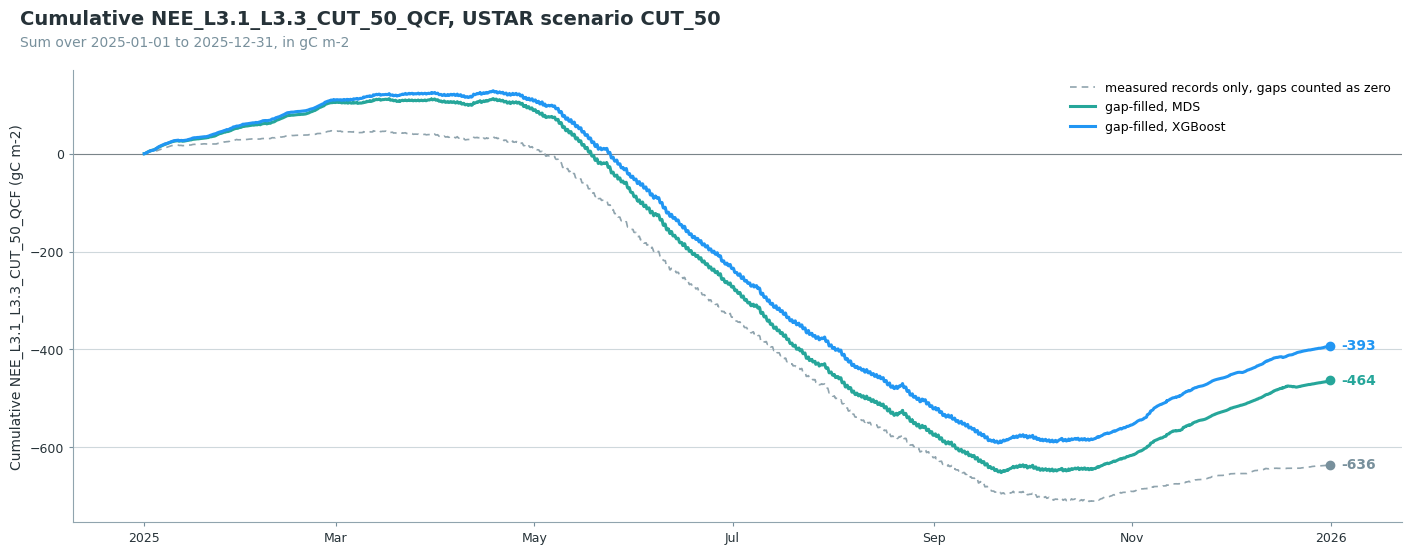

In [47]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative flux of all USTAR scenarios

One line per gap-filling method and USTAR scenario, each method in its own colour. The spread
between CUT_16, CUT_50 and CUT_84 shows how much the annual sum depends on the USTAR threshold. It also contains the variation of the gap-filling model, which
changes with the records each scenario keeps.

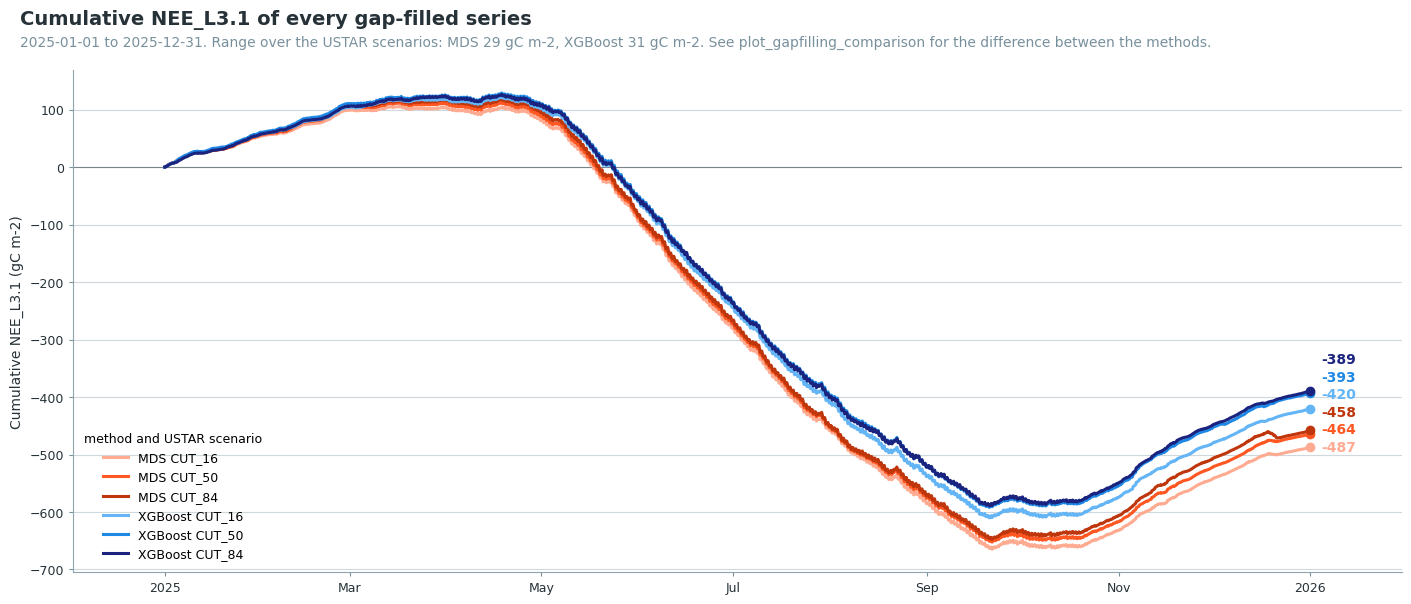

In [48]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative flux per year, for each scenario

One line per year, with the mean of all years plus and minus one standard deviation as a band. In
2016 about 108 days have no measurements: 1 to 10 January, before the first record, and 11 to
22 January and 1 March to 25 May, the start-up periods removed by hand. These include the leaf-out
in spring. The model fills them and learns that season from 2017 and 2018. 2026 ends on
30 September, so its total cannot be compared with full years.

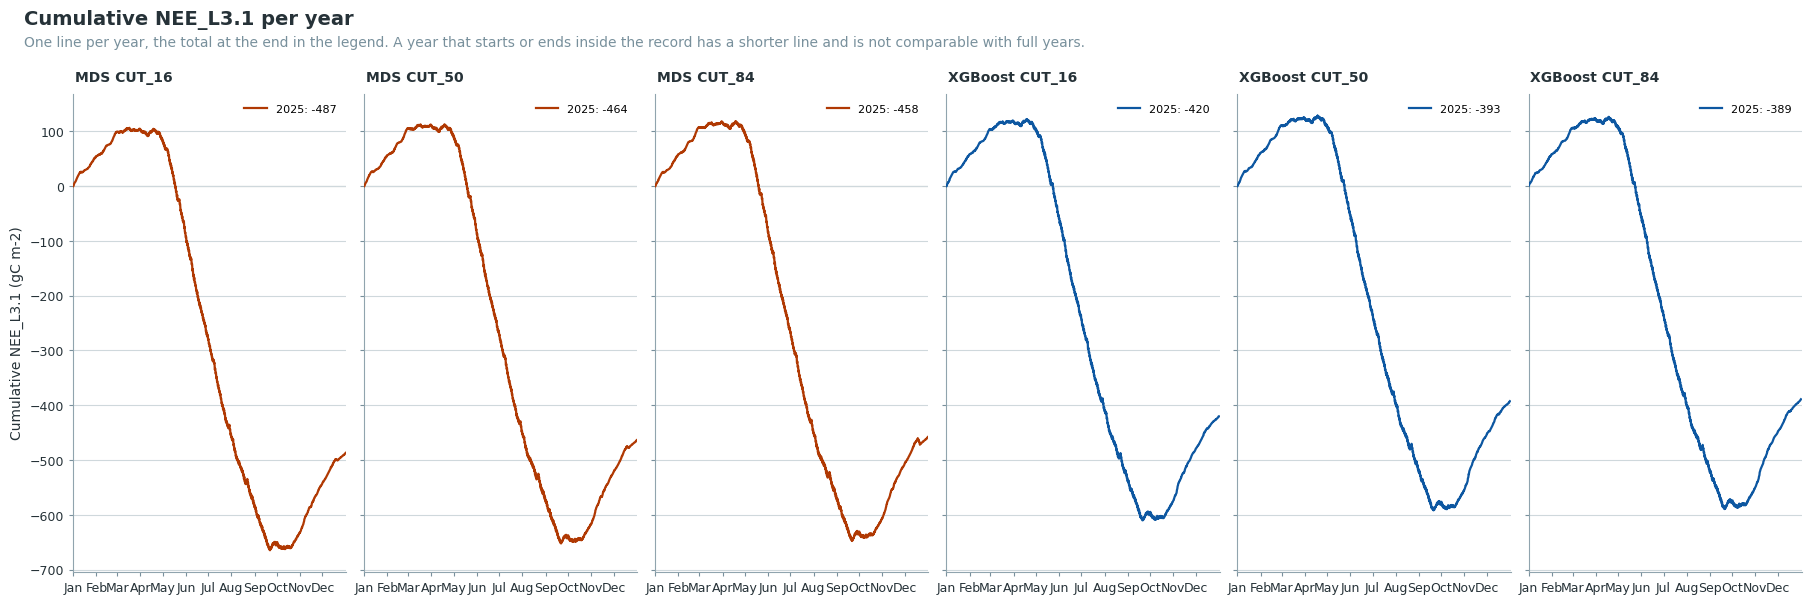

In [49]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=True,
)

### Gap-filling methods compared

Both methods fill the same gaps, so the difference between their sums comes from the filled
values alone. The table splits that difference into daytime and nighttime gaps and by gap length,
and scores both methods on the same held-out records: the test records of XGBoost, which MDS also
predicts without using them. These are random single half-hours, so the scores describe short
gaps, while the sums depend more on the long ones.

**Skipped** when `RUN_MDS = False`.

#### 📋 Table: MDS and XGBoost, sums and their difference

In [50]:
if RUN_MDS:
    report_gapfilling_comparison(data, methods=('mds', 'xgb'), gain=UMOL_TO_GC, units='gC m-2');

Gap-filling methods compared: MDS and XGBoost
          sum       sum                    from         from   gaps   gaps    gaps   gaps
USTAR     MDS   XGBoost   difference   day gaps   night gaps      1   2-12   13-48    >48
─────────────────────────────────────────────────────────────────────────────────────────
CUT_16   -487      -420           67         62            4      1     34      26      5
CUT_50   -464      -393           71         65            6      1     34      27      9
CUT_84   -458      -389           69         72           -3      1     23      25     20
Sums (gC m-2). difference = XGBoost - MDS over the filled gaps, split into daytime and nighttime 
gaps and by gap length in records.
CUT_16, same 2,389 held-out records: MDS R² 0.70 RMSE 6.12, XGBoost R² 0.78 RMSE 5.23
CUT_50, same 2,235 held-out records: MDS R² 0.73 RMSE 5.89, XGBoost R² 0.79 RMSE 5.24
CUT_84, same 2,060 held-out records: MDS R² 0.71 RMSE 6.21, XGBoost R² 0.79 RMSE 5.34
Held-out records are random single half-hours, so these scores describe short gaps; the sums depend 
more on the long ones.

#### 📊 Plot: where MDS and XGBoost differ

The filled values of both methods at the same gaps, their mean difference by month and hour, the
contribution of each month to the difference of the sums, and the cumulative difference for every
USTAR scenario.

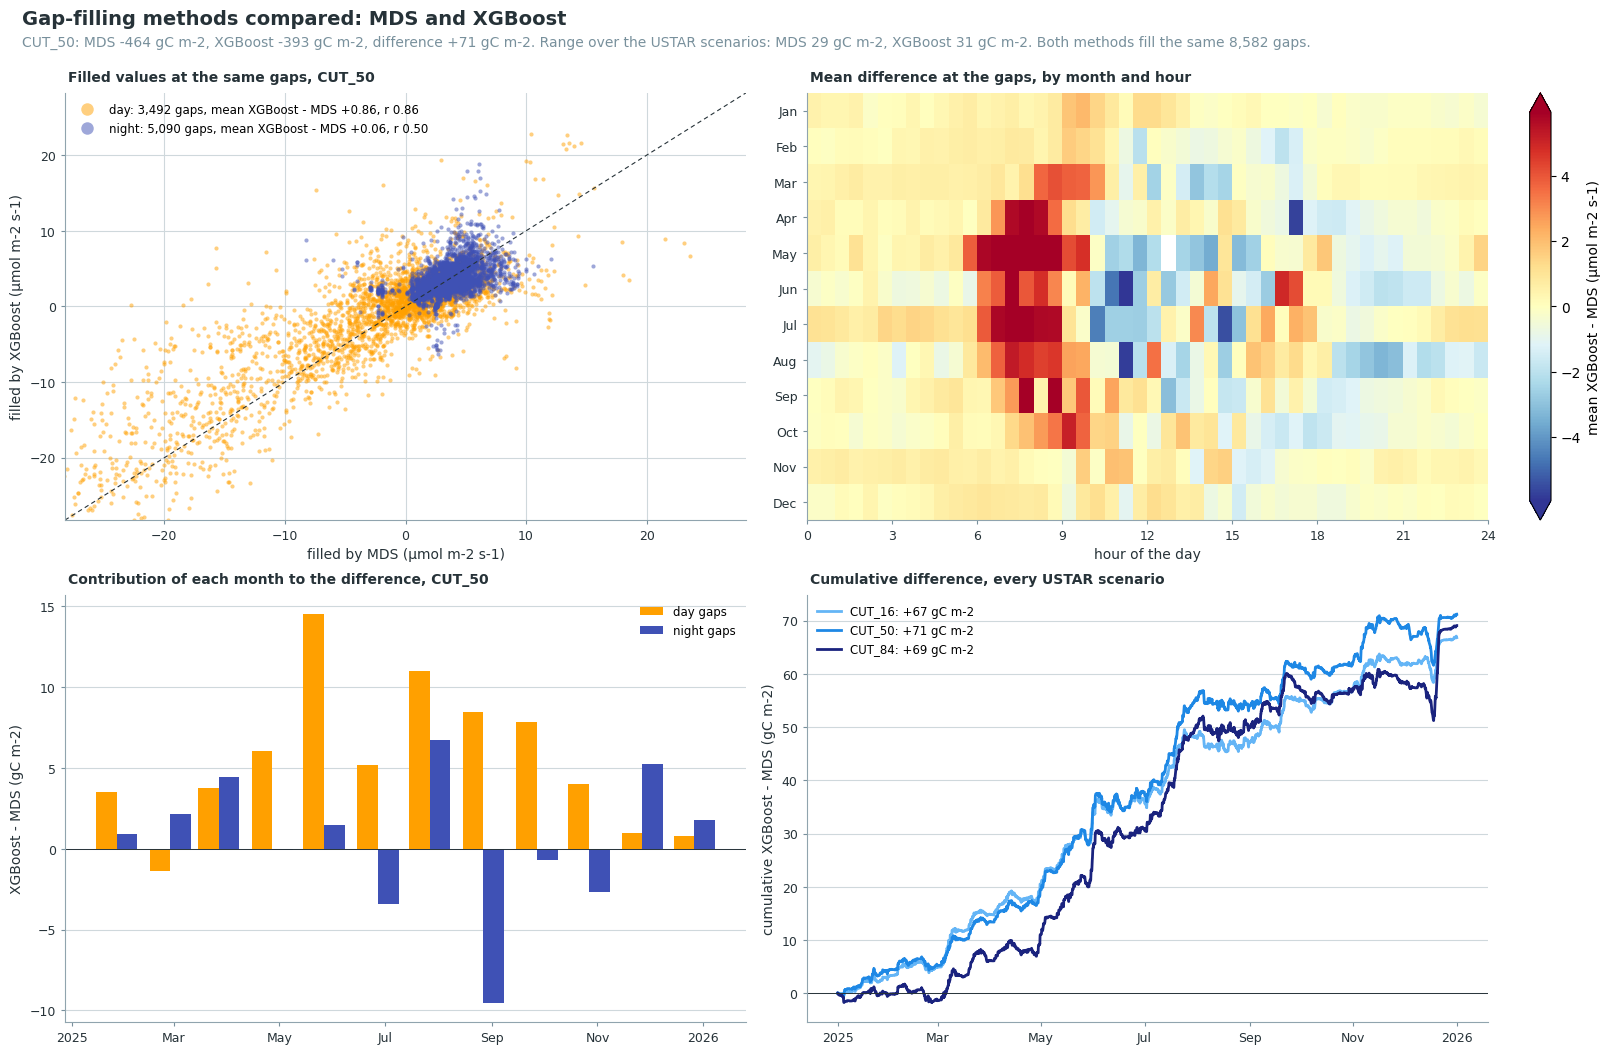

In [51]:
if RUN_MDS:
    plot_gapfilling_comparison(data, ustar_scenario='CUT_50', methods=('mds', 'xgb'),
                               gain=UMOL_TO_GC, units='gC m-2', flux_units=FLUX_UNITS);

## 💾 Step 12: export

`merged_df()` returns the input columns, unchanged, together with every column the chain added.

In [52]:
out_df = data.merged_df()
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 63 (L2: 12, L3.1: 9, L3.2: 9, L3.3: 21, L4.1:
12)

> No variables in the input data were overwritten, only new variables added.

17,520 records x 415 columns


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\01_FPPC_IRGA72_2016-2026.09_TEST_2025.parquet (0.405 seconds).

***

# End of notebook.

In [53]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-26 11:01:11
Finished: 2026-10-26 11:01:50
Runtime:  00:00:39 (hh:mm:ss)
